# **Project Name**    - Flight Price Prediction (Travel MLOps Capstone)

##### **Project Type**    - Regression
##### **Contribution**    - Individual
##### **Team Member 1 -** Anson Sibi

# **Project Summary -**

Travel platforms quote thousands of flight prices every day, and a price that is too high loses the booking while a price that is too low loses margin. In this project I built a regression model that predicts the ticket price of a flight from the information available at booking time, and then took that model all the way to a production-style deployment.

The data comes from a travel company and has three linked tables: **users** (1,340 customers with company, gender and age), **flights** (271,888 flight legs covering 135,944 trips between 9 Brazilian cities) and **hotels** (40,552 hotel stays). The tables connect through `userCode` (user → flights/hotels) and `travelCode` (a trip → its flights and, for about 30% of trips, a hotel stay). This notebook works on `flights.csv`.

**Data understanding.** The flights data is clean: no missing values and no duplicate rows. Every route (origin → destination) always has the same distance and duration, the three classes (economic, premium, firstClass) are sold by three agencies, and FlyingDrops only sells first class. The key finding of the EDA is that **price is fully determined by route + class + agency**: each of the 490 combinations always has exactly one price. Price grows almost linearly with distance, and first class costs about 1.8× economy. Dates matter only indirectly (the route mix differs by weekday), and there is no real monthly seasonality.

**Hypothesis testing.** I tested three statements: (1) mean price differs by flight class (Kruskal–Wallis, p ≈ 0, rejected H0); (2) first-class prices differ between agencies (one-way ANOVA, p ≈ 0.0007, so the difference is statistically significant but only ~R$10 in practice); (3) weekend flights cost more than weekday flights (Mann–Whitney U, p ≈ 0). That last result comes from the route mix, not from a weekend surcharge.

**Feature engineering.** I one-hot encoded the four categorical columns, extracted month, day of week and a weekend flag from the date, and created **distance × class** and **time × class** interaction features. These let even a linear model learn a separate price-per-km slope for each class. ID columns were dropped and no scaling was needed for the tree models.

**Modelling.** I compared three models with the same preprocessing pipeline: **Ridge regression** (baseline), **Random Forest** and **Histogram Gradient Boosting**, each tuned with cross-validated search. Tuned Gradient Boosting gave the best test performance (RMSE < R$0.01, R² ≈ 1.000), followed closely by Random Forest (RMSE ≈ R$0.8), while Ridge reached R² ≈ 0.94 (RMSE ≈ R$88). Because a random split puts every route in both train and test, I also evaluated **generalisation to unseen routes** with GroupKFold. There Ridge (R² ≈ 0.87) beat the tree models (≈ 0.69–0.74), which shows that the trees memorise route prices. I chose Gradient Boosting for production because every route the business sells exists in the training data, and I kept the unseen-route score as a monitoring metric. Permutation importance shows class, distance and agency drive the price.

**MLOps.** The final pipeline (preprocessing + model) is saved with joblib and served by a **Flask REST API**. It is packaged with **Docker**, deployed on **Kubernetes** with probes and a CPU-based autoscaler, retrained weekly by an **Apache Airflow** DAG with a daily drift-monitoring DAG, tracked and versioned in the **MLflow** model registry (champion/challenger aliases), and shipped through a **Jenkins** CI/CD pipeline (lint → tests → quality gate → build → smoke test → deploy, with automatic rollback).

# **GitHub Link -**

https://github.com/ansonsibi/travel-mlops-capstone

# **Problem Statement**

**Build a regression model that predicts the price of a flight from `flights.csv`** using the route (origin, destination), flight class, agency, duration, distance and date, so that the travel platform can quote accurate prices in real time. The model must be accurate, validated properly, and ready to be served through a REST API as part of an automated MLOps pipeline.

# **General Guidelines** : -

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.

     The additional credits will have advantages over other students during Star Student selection.

             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.

```
# Chart visualization code
```

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.

[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]

6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.

*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.

*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, KFold, RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.feature_selection import mutual_info_regression

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

### Dataset Loading

In [2]:
# The notebook works both locally (repo checkout) and on Google Colab.
# Locally it reads ../data/raw/, on Colab it downloads the same CSVs from the GitHub repo.
GITHUB_RAW = "https://raw.githubusercontent.com/ansonsibi/travel-mlops-capstone/main/data/raw/"
LOCAL_DIR = "../data/raw/"


def read_dataset(file_name: str) -> pd.DataFrame:
    """Read a CSV from the local repo if present, otherwise from GitHub."""
    local_path = os.path.join(LOCAL_DIR, file_name)
    source = local_path if os.path.exists(local_path) else GITHUB_RAW + file_name
    try:
        return pd.read_csv(source)
    except Exception as exc:  # network issues / wrong path
        raise RuntimeError(f"Could not load {file_name} from {source}: {exc}")


# Load Dataset
flights_raw = read_dataset("flights.csv")
df = flights_raw.copy()

### Dataset First View

In [3]:
# Dataset First Look
df.head(10)

,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,09/26/2019
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,09/30/2019
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,10/03/2019
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,10/04/2019
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,10/10/2019
5,2,0,Salvador (BH),Aracaju (SE),firstClass,1531.92,2.16,830.86,CloudFy,10/12/2019
6,3,0,Aracaju (SE),Campo Grande (MS),economic,743.54,1.69,650.10,Rainbow,10/17/2019
7,3,0,Campo Grande (MS),Aracaju (SE),economic,877.56,1.69,650.10,Rainbow,10/20/2019
8,4,0,Recife (PE),Florianopolis (SC),economic,803.39,1.76,676.53,Rainbow,10/24/2019
9,4,0,Florianopolis (SC),Recife (PE),economic,695.30,1.76,676.53,Rainbow,10/26/2019


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")

Rows: 271,888  Columns: 10


### Dataset Information

In [5]:
# Dataset Info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 271888 entries, 0 to 271887
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   travelCode  271888 non-null  int64  
 1   userCode    271888 non-null  int64  
 2   from        271888 non-null  str    
 3   to          271888 non-null  str    
 4   flightType  271888 non-null  str    
 5   price       271888 non-null  float64
 6   time        271888 non-null  float64
 7   distance    271888 non-null  float64
 8   agency      271888 non-null  str    
 9   date        271888 non-null  str    
dtypes: float64(3), int64(2), str(5)
memory usage: 35.0 MB


#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Duplicate rows:", df.duplicated().sum())
# a trip (travelCode) has an outbound and a return leg, so duplicates of the trip id are expected
print("Legs per trip:", df.groupby("travelCode").size().value_counts().to_dict())

Duplicate rows: 0
Legs per trip: {2: 135944}


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
df.isnull().sum()

travelCode    0
userCode      0
from          0
to            0
flightType    0
price         0
time          0
distance      0
agency        0
date          0
dtype: int64

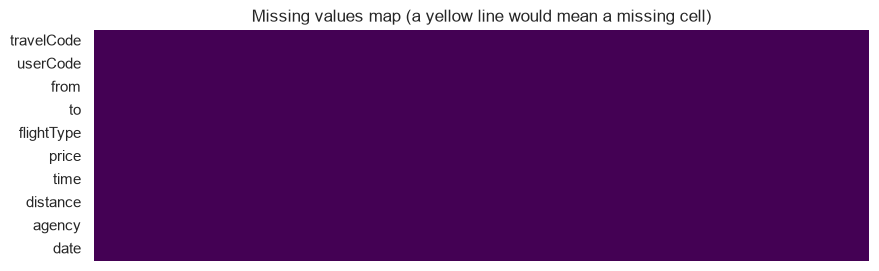

In [8]:
# Visualizing the missing values
plt.figure(figsize=(10, 3))
sns.heatmap(df.isnull().T, cbar=False, yticklabels=True, xticklabels=False, cmap="viridis")
plt.title("Missing values map (a yellow line would mean a missing cell)")
plt.show()

### What did you know about your dataset?

* The flights table has **271,888 rows and 10 columns**: two IDs (`travelCode`, `userCode`), four categorical columns (`from`, `to`, `flightType`, `agency`), three numeric columns (`price`, `time`, `distance`) and a `date` stored as text (MM/DD/YYYY).
* There are **no missing values and no duplicate rows**, so no imputation is needed.
* Every `travelCode` has exactly two legs (outbound + return), so one trip = two rows.
* The target is `price` (a continuous value in Brazilian Reais), which makes this a **regression** problem.

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
list(df.columns)

['travelCode',
 'userCode',
 'from',
 'to',
 'flightType',
 'price',
 'time',
 'distance',
 'agency',
 'date']

In [10]:
# Dataset Describe
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
travelCode,271888.0,NaN,NaN,NaN,67971.5,39243.724665,0.0,33985.75,67971.5,101957.25,135943.0
userCode,271888.0,NaN,NaN,NaN,667.505495,389.523127,0.0,326.0,659.0,1011.0,1339.0
from,271888,9,Florianopolis (SC),57317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
to,271888,9,Florianopolis (SC),57317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flightType,271888,3,firstClass,116418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,271888.0,NaN,NaN,NaN,957.37503,362.31189,301.51,672.66,904.0,1222.24,1754.17
time,271888.0,NaN,NaN,NaN,1.421147,0.542541,0.44,1.04,1.46,1.76,2.44
distance,271888.0,NaN,NaN,NaN,546.955535,208.851288,168.22,401.66,562.14,676.53,937.77
agency,271888,3,Rainbow,116752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,271888,999,09/26/2019,1335,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description 

| Variable | Type | Description |
|---|---|---|
| `travelCode` | int (ID) | Identifier of the trip. Outbound and return legs share the same code. Not a feature. |
| `userCode` | int (ID) | Customer who booked the flight (links to `users.csv`). Not a feature. |
| `from` | categorical | Origin city (9 cities). |
| `to` | categorical | Destination city (9 cities). |
| `flightType` | categorical | Class of the ticket: `economic`, `premium`, `firstClass`. |
| `price` | float | **Target** – ticket price of the leg. |
| `time` | float | Flight duration in hours. |
| `distance` | float | Flight distance in km. |
| `agency` | categorical | Selling agency: `Rainbow`, `CloudFy`, `FlyingDrops`. |
| `date` | date | Date of the flight (2019-09 to 2023-07). |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for col in df.columns:
    print(f"{col:<12} {df[col].nunique():>7} unique values")
print()
for col in ["from", "to", "flightType", "agency"]:
    print(col, "->", sorted(df[col].unique()))

travelCode    135944 unique values
userCode        1335 unique values
from               9 unique values
to                 9 unique values
flightType         3 unique values
price            490 unique values
time              33 unique values
distance          35 unique values
agency             3 unique values
date             999 unique values

from -> ['Aracaju (SE)', 'Brasilia (DF)', 'Campo Grande (MS)', 'Florianopolis (SC)', 'Natal (RN)', 'Recife (PE)', 'Rio de Janeiro (RJ)', 'Salvador (BH)', 'Sao Paulo (SP)']
to -> ['Aracaju (SE)', 'Brasilia (DF)', 'Campo Grande (MS)', 'Florianopolis (SC)', 'Natal (RN)', 'Recife (PE)', 'Rio de Janeiro (RJ)', 'Salvador (BH)', 'Sao Paulo (SP)']
flightType -> ['economic', 'firstClass', 'premium']
agency -> ['CloudFy', 'FlyingDrops', 'Rainbow']


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.day_of_week          # 0 = Monday
df["day_name"] = df["date"].dt.day_name()
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["route"] = df["from"] + " → " + df["to"]
df["price_per_km"] = df["price"] / df["distance"]      # analysis only - leaks the target, never a feature

# 1) does each route always have the same distance / duration?
route_check = df.groupby("route").agg(distance_values=("distance", "nunique"), time_values=("time", "nunique"))
print("Routes:", len(route_check), "| routes with >1 distance:", (route_check["distance_values"] > 1).sum(),
      "| routes with >1 duration:", (route_check["time_values"] > 1).sum())

# 2) how many different prices does a route + class + agency combination have?
combo_prices = df.groupby(["from", "to", "flightType", "agency"])["price"].nunique()
print("route/class/agency combinations:", len(combo_prices),
      "| combinations with more than one price:", (combo_prices > 1).sum())

# 3) which agency sells which class?
print()
print(pd.crosstab(df["agency"], df["flightType"]))

Routes: 70 | routes with >1 distance: 0 | routes with >1 duration: 0
route/class/agency combinations: 490 | combinations with more than one price: 0

flightType   economic  firstClass  premium
agency                                    
CloudFy         38656       38862    38860
FlyingDrops         0       38758        0
Rainbow         38810       38798    39144


### What all manipulations have you done and insights you found?

**Manipulations**
* Converted `date` from text to datetime and derived `year`, `month`, `day_of_week`, `day_name` and `is_weekend`.
* Created `route` (origin → destination) for analysis, and `price_per_km` for EDA only. `price_per_km` is built from the target, so it would leak the answer and is never used as a model feature.

**Insights**
* There are **72 directed routes** and each one always has the same distance and duration, so `time` and `distance` describe the route rather than the individual flight.
* Each of the **490 route × class × agency combinations always has exactly one price**. The pricing is a deterministic tariff table, so a good model should be able to predict prices almost perfectly for known routes.
* FlyingDrops only sells first class, while CloudFy and Rainbow sell all three classes.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Distribution of flight prices (Univariate)

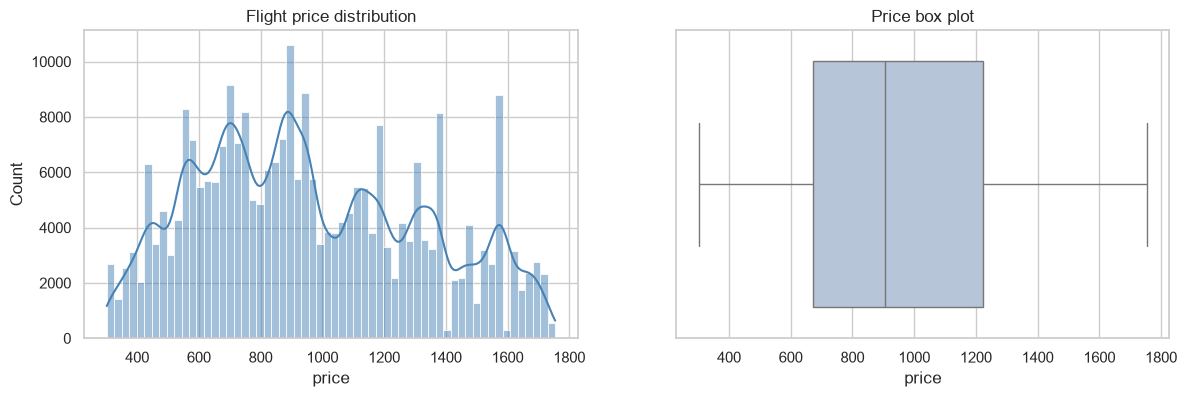

skewness = 0.31


In [13]:
# Chart - 1 visualization code
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df["price"], bins=60, kde=True, ax=ax[0], color="steelblue")
ax[0].set_title("Flight price distribution")
sns.boxplot(x=df["price"], ax=ax[1], color="lightsteelblue")
ax[1].set_title("Price box plot")
plt.show()
print(f"skewness = {df['price'].skew():.2f}")

##### 1. Why did you pick the specific chart?

A histogram with a KDE shows the shape of the target distribution (skew, modes, spread), and the box plot next to it highlights outliers. It is the first thing to check before choosing a loss function or a transformation.

##### 2. What is/are the insight(s) found from the chart?

Prices range from about R$300 to R$1,750 with a mean of about R$957. The distribution is **multi-modal**, with separate humps for economy, premium and first class, and only slightly right-skewed (skew ≈ 0.31). The box plot shows **no outliers**.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. With no outliers and a mild skew, the model can be trained on the raw price without a log transform. The separate humps tell us class is the main driver of price, which helps with pricing segmentation. Nothing here points to negative growth.

#### Chart - 2 - Number of flights per class and agency (Univariate)

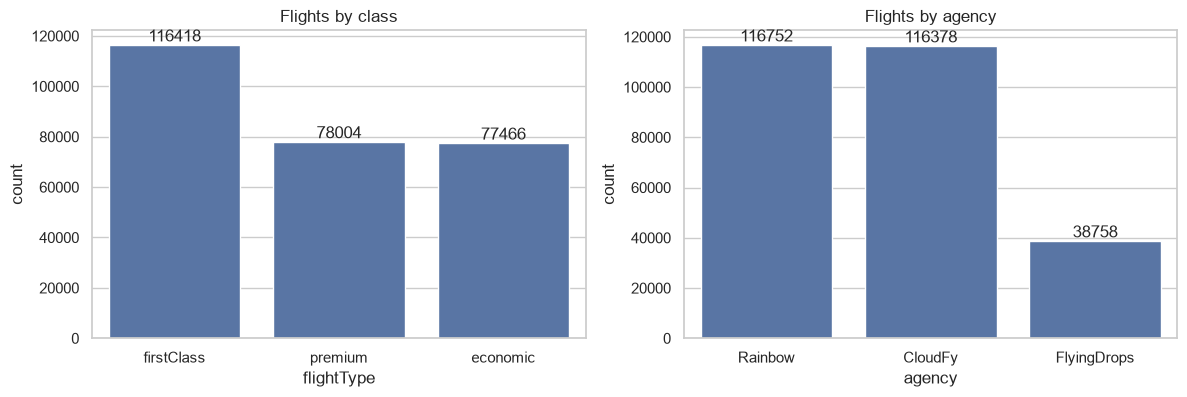

In [14]:
# Chart - 2 visualization code
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
order = df["flightType"].value_counts().index
sns.countplot(data=df, x="flightType", order=order, ax=ax[0])
ax[0].set_title("Flights by class")
sns.countplot(data=df, x="agency", order=df["agency"].value_counts().index, ax=ax[1])
ax[1].set_title("Flights by agency")
for a in ax:
    for c in a.containers:
        a.bar_label(c, fmt="%d")
plt.show()

##### 1. Why did you pick the specific chart?

Count plots are the simplest way to compare category frequencies and check class balance.

##### 2. What is/are the insight(s) found from the chart?

First class is the most sold class (~43%), with premium and economy at ~29% each. Rainbow and CloudFy each handle ~43% of flights, while FlyingDrops has ~14% (because it only sells first class).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. First class is both the most frequent and the most expensive class, so pricing errors there cost the most and that segment deserves the most accuracy. FlyingDrops depends on a single class, which makes it vulnerable if first-class demand drops.

#### Chart - 3 - Price by flight class (Bivariate: categorical vs numeric)

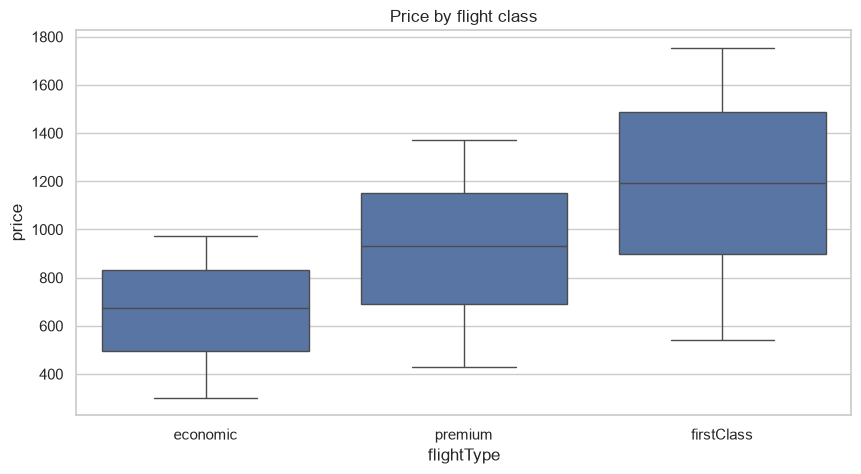

              mean  median    std
flightType                       
economic     658.4   674.5  192.9
premium      920.4   932.8  276.9
firstClass  1181.1  1190.9  346.4


In [15]:
# Chart - 3 visualization code
order = ["economic", "premium", "firstClass"]
sns.boxplot(data=df, x="flightType", y="price", order=order)
plt.title("Price by flight class")
plt.show()
print(df.groupby("flightType")["price"].agg(["mean", "median", "std"]).loc[order].round(1))

##### 1. Why did you pick the specific chart?

A box plot compares the full distribution of a numeric variable across categories (median, spread, overlap).

##### 2. What is/are the insight(s) found from the chart?

Mean price is about R$658 for economy, R$920 for premium and R$1,181 for first class, so first class is roughly 1.8× economy. The ranges overlap because a long economy flight can cost more than a short first-class one, which means distance also matters.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It quantifies the premium customers pay for an upgrade, which is useful for upsell offers such as "upgrade to premium for +R$260". The overlap shows that class alone cannot price a ticket and distance is needed too.

#### Chart - 4 - Price by agency within each class (Multivariate)

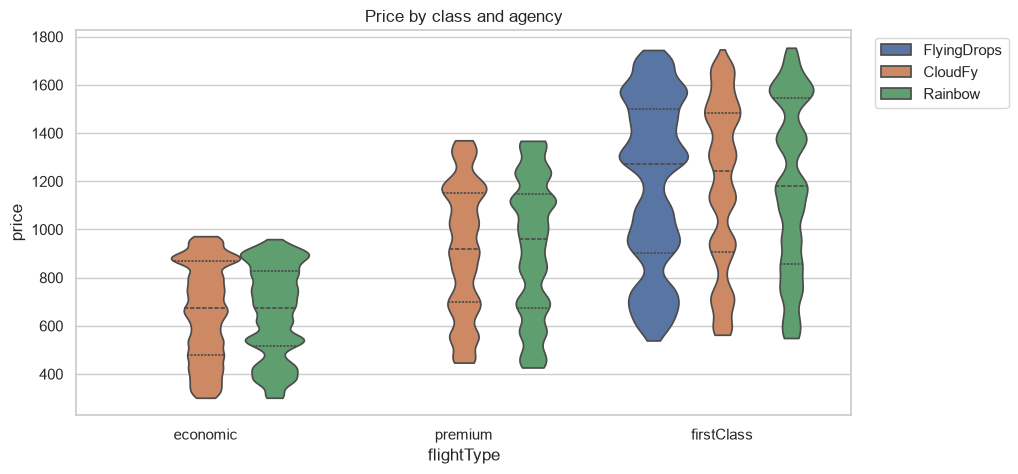

In [16]:
# Chart - 4 visualization code
sns.violinplot(data=df, x="flightType", y="price", hue="agency", order=order, cut=0, inner="quartile")
plt.title("Price by class and agency")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

##### 1. Why did you pick the specific chart?

A grouped violin plot shows the price distribution for every class × agency combination in one figure, so agencies can be compared like for like within the same class.

##### 2. What is/are the insight(s) found from the chart?

Within a given class the agencies charge almost the same: the violins have nearly identical shapes and medians. Agency on its own adds very little once class is known.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Agencies compete on almost identical prices, so price is not a differentiator between them, and the platform could compete on service or bundles (for example flight + hotel) instead. No negative-growth signal.

#### Chart - 5 - Agency × class availability (Categorical vs categorical)

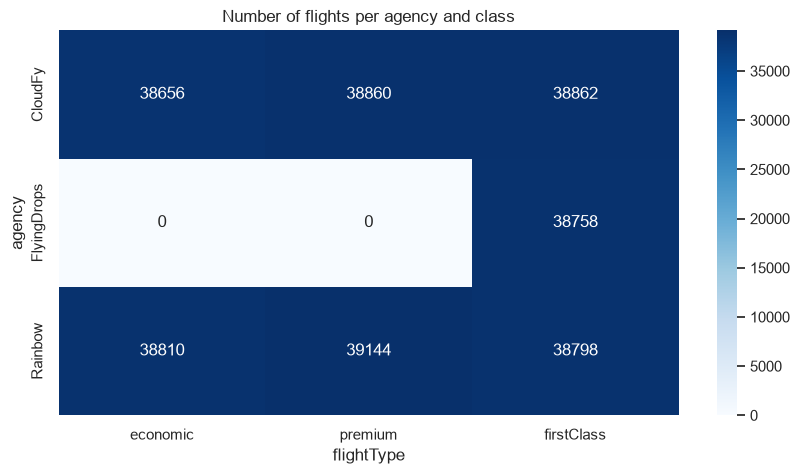

In [17]:
# Chart - 5 visualization code
ct = pd.crosstab(df["agency"], df["flightType"])[order]
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues")
plt.title("Number of flights per agency and class")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of a crosstab shows how two categorical variables co-occur, including combinations that never happen.

##### 2. What is/are the insight(s) found from the chart?

FlyingDrops has **zero** economy and premium flights. The other two agencies split all classes almost evenly.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The model will never see FlyingDrops + economy, so the API must reject or flag such requests instead of returning an unreliable price; the API validates inputs for exactly this reason. FlyingDrops also has a gap in its product range that a competitor could exploit.

#### Chart - 6 - Distance vs price (Numeric vs numeric)

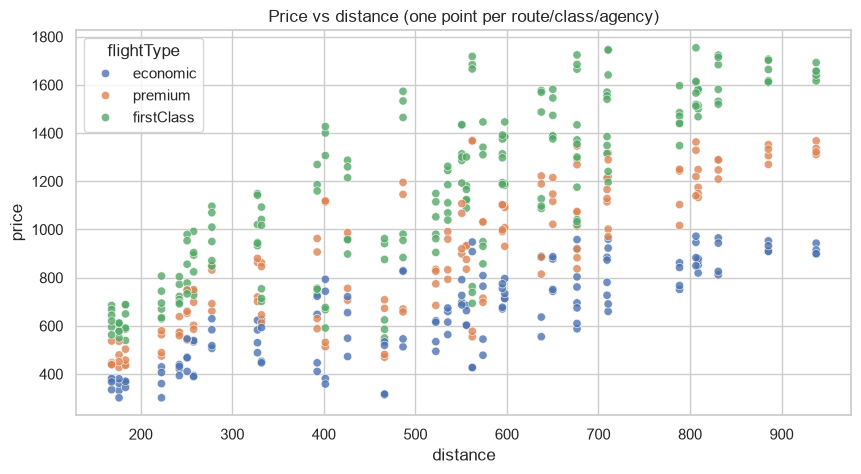

economic    price ≈  252.6 + 0.76 × km   (r = 0.84)
premium     price ≈  329.5 + 1.10 × km   (r = 0.85)
firstClass  price ≈  436.4 + 1.38 × km   (r = 0.84)


In [18]:
# Chart - 6 visualization code
combos = df.drop_duplicates(["from", "to", "flightType", "agency"])
sns.scatterplot(data=combos, x="distance", y="price", hue="flightType", hue_order=order, alpha=0.8)
plt.title("Price vs distance (one point per route/class/agency)")
plt.show()
for cls in order:
    sub = combos[combos["flightType"] == cls]
    slope, intercept, r, *_ = stats.linregress(sub["distance"], sub["price"])
    print(f"{cls:<11} price ≈ {intercept:6.1f} + {slope:.2f} × km   (r = {r:.2f})")

##### 1. Why did you pick the specific chart?

A scatter plot is the standard way to see the relationship between two numeric variables. I plotted one point per unique tariff so that the 270k rows don't hide the structure.

##### 2. What is/are the insight(s) found from the chart?

Price rises roughly **linearly with distance**, with a different slope for each class (about 0.76, 1.10 and 1.38 R$ per km for economy, premium and first class, r ≈ 0.84). The points spread around each line, so every route also has its own adjustment.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows the pricing logic is distance-based with a class multiplier, which led me to create **distance × class interaction features** so that a linear model can learn one slope per class. It also gives a quick way to estimate a price for a brand-new route.

#### Chart - 7 - Duration vs distance (Numeric vs numeric)

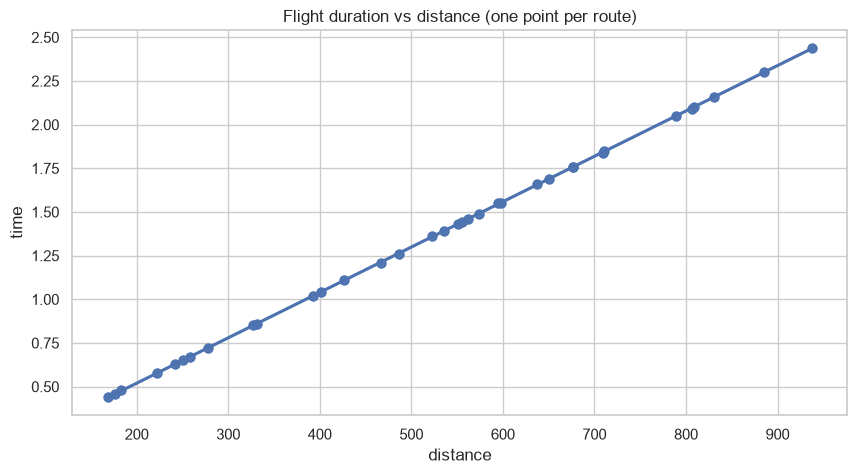

correlation: 0.99999


In [19]:
# Chart - 7 visualization code
routes = df.drop_duplicates("route")
sns.regplot(data=routes, x="distance", y="time", scatter_kws={"s": 40})
plt.title("Flight duration vs distance (one point per route)")
plt.show()
print("correlation:", round(routes["time"].corr(routes["distance"]), 5))

##### 1. Why did you pick the specific chart?

A scatter plot with a fitted line tests whether two numeric features carry the same information (multicollinearity).

##### 2. What is/are the insight(s) found from the chart?

Duration and distance are almost perfectly correlated (r ≈ 0.99999): duration is distance divided by a constant cruise speed.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

For the business, duration can be shown to customers without a separate data source. For modelling, the two features are redundant: harmless for trees, but for the linear model it means one coefficient can't be interpreted without the other. I keep both because the API receives both.

#### Chart - 8 - Average price by origin city (Univariate aggregate)

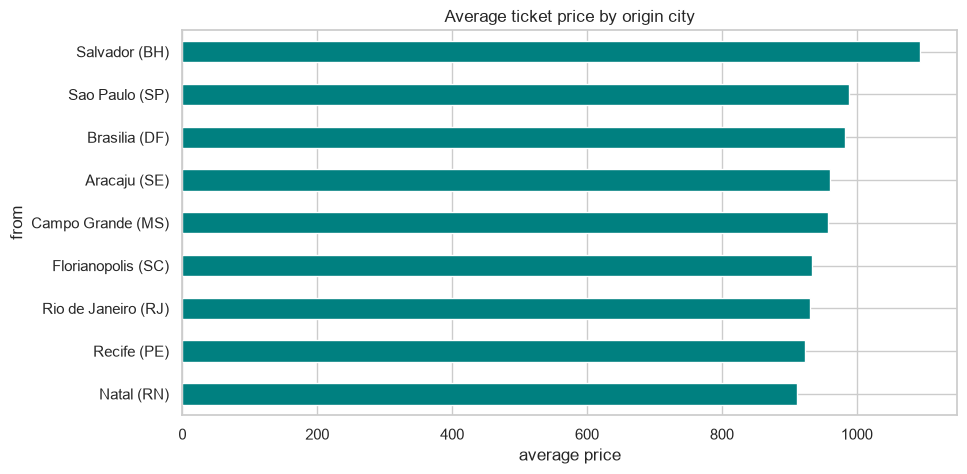

In [20]:
# Chart - 8 visualization code
avg_origin = df.groupby("from")["price"].mean().sort_values()
avg_origin.plot(kind="barh", color="teal")
plt.xlabel("average price")
plt.title("Average ticket price by origin city")
plt.show()

##### 1. Why did you pick the specific chart?

A sorted horizontal bar chart makes it easy to compare an aggregate across many categories with long names.

##### 2. What is/are the insight(s) found from the chart?

Flights from **Salvador** are the most expensive on average (≈ R$1,094) and flights from Natal the cheapest (≈ R$911). This mainly reflects how far each city is from the others.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Marketing can target price-sensitive customers with deals from the cheaper hubs. Salvador's higher fares could reduce demand there, a possible negative-growth area worth promotions.

#### Chart - 9 - Average price for every route (Multivariate heatmap)

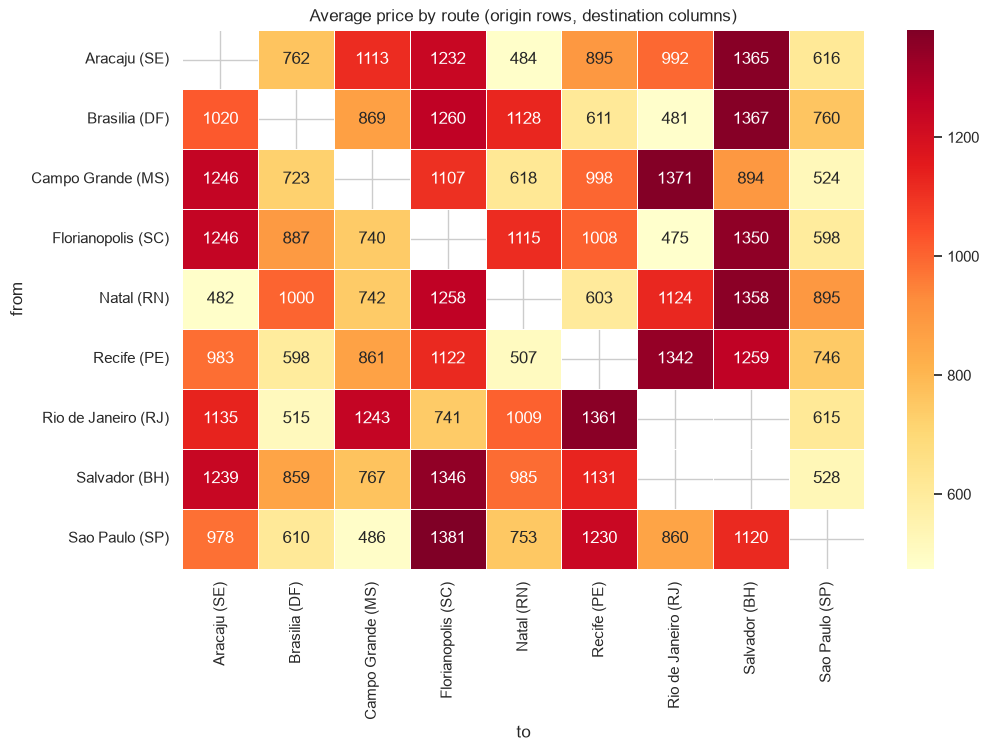

In [21]:
# Chart - 9 visualization code
pivot = df.pivot_table(index="from", columns="to", values="price", aggfunc="mean")
plt.figure(figsize=(11, 7))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlOrRd", linewidths=0.5)
plt.title("Average price by route (origin rows, destination columns)")
plt.show()

##### 1. Why did you pick the specific chart?

A heatmap of the origin × destination matrix shows every route's average price at once and makes the symmetry between outbound and return legs easy to see.

##### 2. What is/are the insight(s) found from the chart?

The matrix is symmetric (A→B costs about the same as B→A) and there are no flights from a city to itself. The most expensive routes involve Salvador and Florianópolis, which are far apart.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Symmetric pricing means return tickets can be bundled with a predictable total. The most expensive routes are where a small discount might win share, while cheap short routes have thin margins.

#### Chart - 10 - Flights over time (Time series)

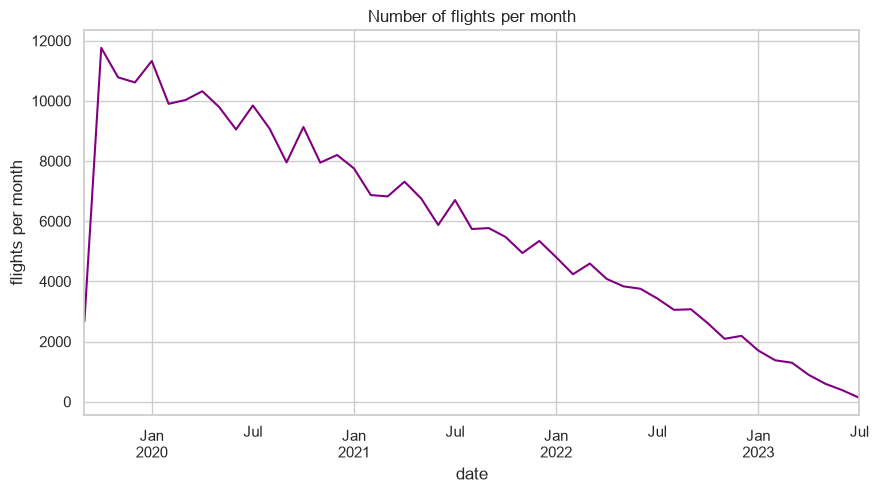

In [22]:
# Chart - 10 visualization code
monthly = df.set_index("date").resample("ME").size()
monthly.plot(color="purple")
plt.ylabel("flights per month")
plt.title("Number of flights per month")
plt.show()

##### 1. Why did you pick the specific chart?

A line chart is the right choice to show how a quantity evolves over time.

##### 2. What is/are the insight(s) found from the chart?

Volume peaks at the end of 2019 and then **declines steadily until mid-2023**. This is how the dataset was generated (each user's trips start at sign-up and spread forward), not an outbreak of demand.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

This is a warning sign: if real, a falling number of bookings means negative growth and the business should check customer retention. For the model it means that recent months have less data, so it's important to check that price does not depend on the date (see next chart).

#### Chart - 11 - Average price by month (Seasonality)

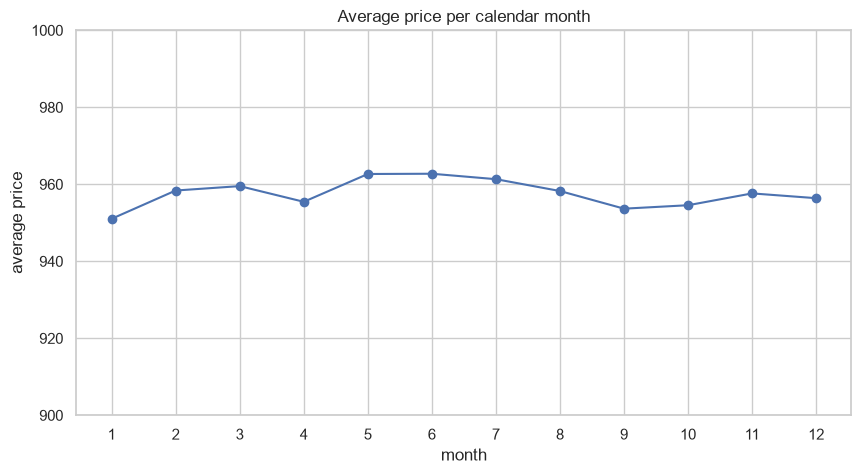

In [23]:
# Chart - 11 visualization code
df.groupby("month")["price"].mean().plot(marker="o")
plt.ylim(900, 1000)
plt.xticks(range(1, 13))
plt.ylabel("average price")
plt.title("Average price per calendar month")
plt.show()

##### 1. Why did you pick the specific chart?

A line chart over the 12 calendar months is the simplest check for seasonality.

##### 2. What is/are the insight(s) found from the chart?

The monthly average stays between ≈ R$951 and R$963, so **there is no meaningful seasonality**. The tariff does not change with the time of year.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Prices are stable, so there are no peak-season revenue opportunities in this tariff yet. Introducing seasonal (dynamic) pricing could be a growth lever. For the model, calendar features will add little.

#### Chart - 12 - Flights and price by day of week

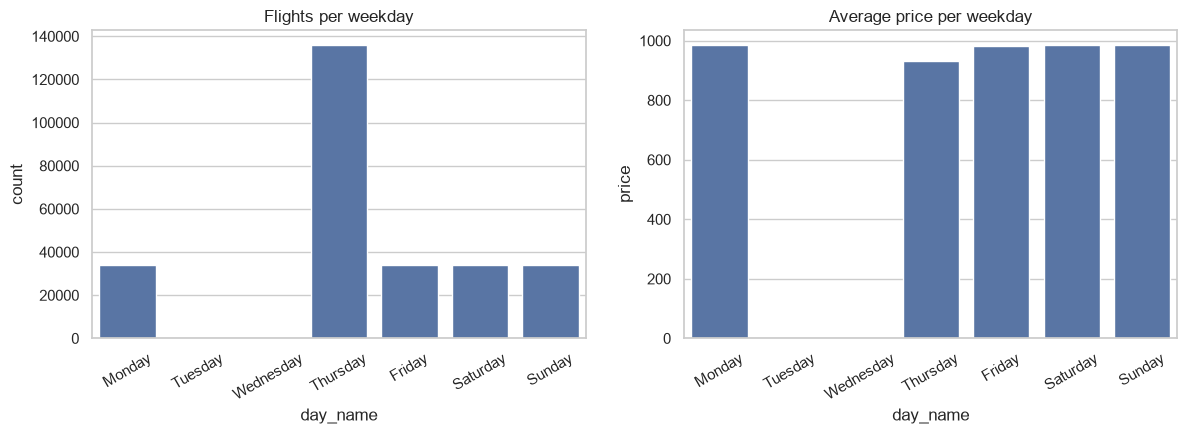

In [24]:
# Chart - 12 visualization code
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sns.countplot(data=df, x="day_name", order=days, ax=ax[0])
ax[0].set_title("Flights per weekday")
ax[0].tick_params(axis="x", rotation=30)
sns.barplot(data=df, x="day_name", y="price", order=days, ax=ax[1], errorbar=None)
ax[1].set_title("Average price per weekday")
ax[1].tick_params(axis="x", rotation=30)
plt.show()

##### 1. Why did you pick the specific chart?

Two bar charts side by side compare volume and price across weekdays.

##### 2. What is/are the insight(s) found from the chart?

Flights only happen on Monday, Thursday, Friday, Saturday and Sunday, and **Thursday has 4× more flights** (it is the typical outbound day). The average price is a bit higher on weekends, but the route/class mix also differs by day (tested in Hypothesis 3).

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Operations can plan capacity for the Thursday peak, and the empty Tuesdays/Wednesdays are an opportunity to sell discounted mid-week trips.

#### Chart - 13 - Flights per user (Univariate)

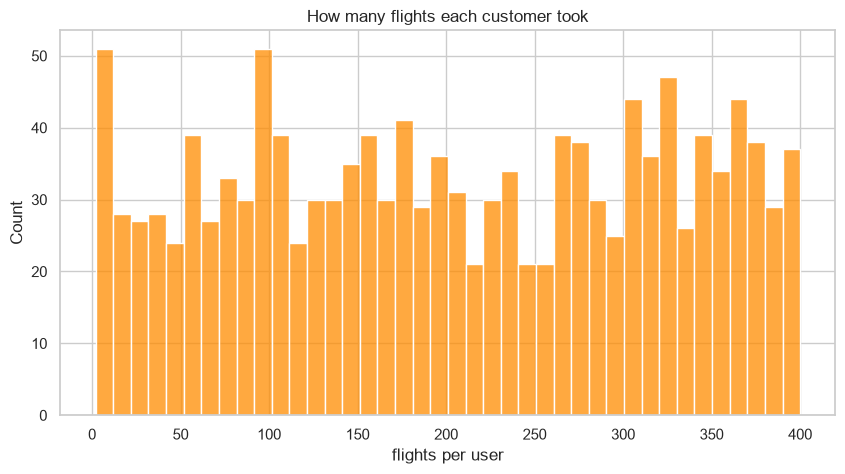

count    1335.0
mean      203.7
std       117.8
min         2.0
25%       100.0
50%       200.0
75%       310.0
max       400.0
dtype: float64


In [25]:
# Chart - 13 visualization code
per_user = df.groupby("userCode").size()
sns.histplot(per_user, bins=40, color="darkorange")
plt.xlabel("flights per user")
plt.title("How many flights each customer took")
plt.show()
print(per_user.describe().round(1))

##### 1. Why did you pick the specific chart?

A histogram of the per-user count shows how activity is spread across customers.

##### 2. What is/are the insight(s) found from the chart?

Customers fly a lot: the median user has 200 flight legs (≈100 trips) and the count is spread evenly between 2 and 400. These are corporate travellers rather than occasional tourists.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. A corporate customer base with high frequency suits loyalty programmes and company-level contracts. Losing a single big user would also cost a lot of volume, a concentration risk.

#### Chart - 14 - Correlation Heatmap

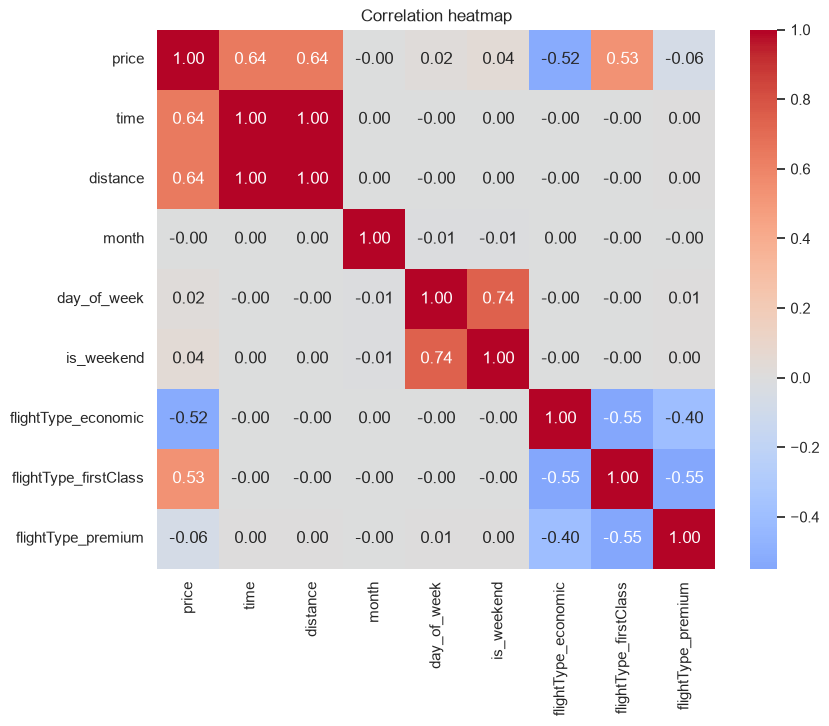

In [26]:
# Correlation Heatmap visualization code
num_cols = ["price", "time", "distance", "month", "day_of_week", "is_weekend"]
corr_df = pd.get_dummies(df[num_cols + ["flightType"]], columns=["flightType"], dtype=float)
plt.figure(figsize=(9, 7))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap summarises all pairwise linear relationships between numeric features (and one-hot encoded class) in one view, and helps detect multicollinearity and strong predictors.

##### 2. What is/are the insight(s) found from the chart?

`price` correlates with `distance`/`time` (≈ 0.64) and strongly with the class dummies (first class +0.69, economy −0.53). `time` and `distance` are almost perfectly correlated with each other. Date features have ~0 correlation with price.

#### Chart - 15 - Pair Plot 

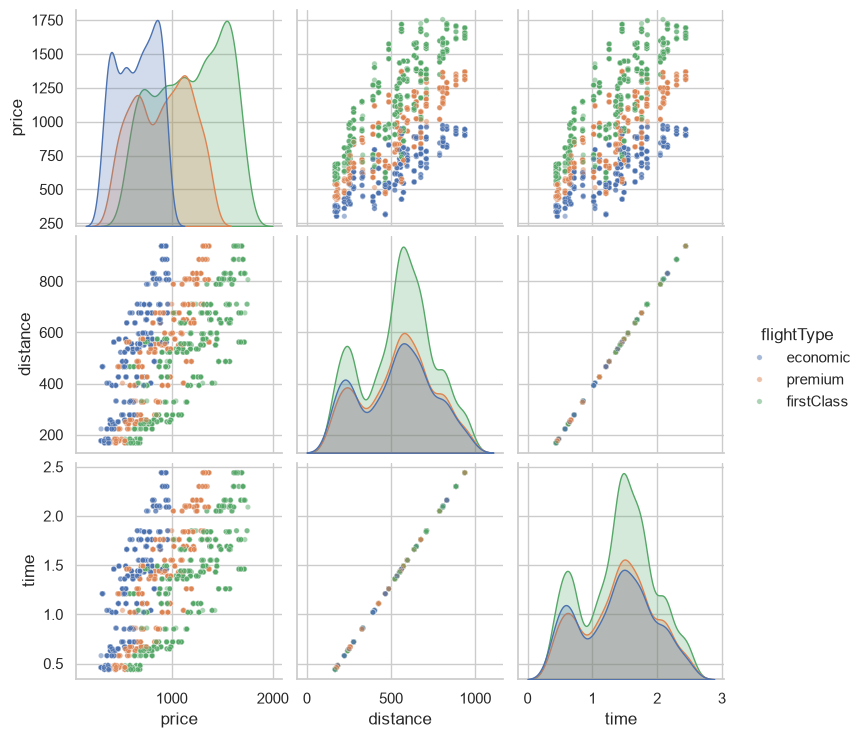

In [27]:
# Pair Plot visualization code
sample = df.sample(3000, random_state=RANDOM_STATE)
sns.pairplot(sample[["price", "distance", "time", "flightType"]], hue="flightType", hue_order=order,
             plot_kws={"alpha": 0.5, "s": 15})
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise scatter plus each feature's distribution, coloured by class, so I can check the multivariate structure in one view (on a 3,000-row sample for speed).

##### 2. What is/are the insight(s) found from the chart?

Each class forms its own band in the price–distance panels, confirming the *distance × class* interaction. The time–distance panel is a straight line (redundant features), and the class distributions of price are clearly separated.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. The average flight price is different for the three flight classes.
2. In first class, the average price differs between agencies.
3. Weekend flights are more expensive than weekday flights.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** The price distribution is the same for economic, premium and firstClass.
* **H1:** At least one class has a different price distribution.

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value
groups = [g["price"].values for _, g in df.groupby("flightType")]
h_stat, p_value = stats.kruskal(*groups)
print(f"Kruskal-Wallis H = {h_stat:,.0f}, p-value = {p_value:.3e}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

Kruskal-Wallis H = 95,517, p-value = 0.000e+00
Reject H0


##### Which statistical test have you done to obtain P-Value?

Kruskal–Wallis H test (non-parametric one-way ANOVA on ranks).

##### Why did you choose the specific statistical test?

We compare more than two independent groups and price is not normally distributed within each class (it's multi-modal because of distance), so a rank-based test is safer than ANOVA. With p ≈ 0 we reject H0: flight class has a significant effect on price.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** In first class, the mean price is the same for CloudFy, FlyingDrops and Rainbow.
* **H1:** At least one agency has a different mean first-class price.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
first = df[df["flightType"] == "firstClass"]
groups = [g["price"].values for _, g in first.groupby("agency")]
f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA F = {f_stat:.2f}, p-value = {p_value:.4f}")
print(first.groupby("agency")["price"].mean().round(2))
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

ANOVA F = 7.29, p-value = 0.0007
agency
CloudFy        1180.29
FlyingDrops    1186.16
Rainbow        1176.76
Name: price, dtype: float64
Reject H0


##### Which statistical test have you done to obtain P-Value?

One-way ANOVA (F-test).

##### Why did you choose the specific statistical test?

We compare the means of three independent groups. With ~39k rows per agency the sample means are approximately normal (Central Limit Theorem), so ANOVA is valid. p ≈ 0.0007 < 0.05, so we reject H0. The difference is *statistically* significant, but it is only about R$10 out of R$1,180, so it barely matters in practice. This is a reminder that with huge samples, tiny effects become significant.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **H0:** Weekend and weekday flights have the same price distribution.
* **H1:** Weekend flights are priced higher than weekday flights.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
weekend = df.loc[df["is_weekend"] == 1, "price"]
weekday = df.loc[df["is_weekend"] == 0, "price"]
u_stat, p_value = stats.mannwhitneyu(weekend, weekday, alternative="greater")
print(f"Mann-Whitney U p-value = {p_value:.3e}")
print(f"mean weekend = {weekend.mean():.1f}, mean weekday = {weekday.mean():.1f}")

# is it a real weekend surcharge, or a different route/class mix on weekends?
same_tariff = df.groupby(["from", "to", "flightType", "agency", "is_weekend"])["price"].mean().unstack()
print("max price difference for the SAME route/class/agency, weekend vs weekday:",
      (same_tariff[1] - same_tariff[0]).abs().max().round(4))

Mann-Whitney U p-value = 1.172e-121
mean weekend = 984.8, mean weekday = 948.3
max price difference for the SAME route/class/agency, weekend vs weekday: 0.0


##### Which statistical test have you done to obtain P-Value?

Mann–Whitney U test (one-sided).

##### Why did you choose the specific statistical test?

We compare two independent groups on a non-normal variable, so a rank-based two-sample test is appropriate. p ≈ 0, so weekend flights are more expensive *on average* and we reject H0. But the follow-up check shows that **for the same route/class/agency the price is identical on weekends**: the difference comes from which routes people fly on weekends (confounding), not from a weekend surcharge. That is why the model doesn't need to rely on the weekend flag.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation
print("Missing cells in the dataset:", int(df.isnull().sum().sum()))
# The production pipeline still guards against a missing date coming from the API:
# it falls back to today's date (see add_engineered_features below).

Missing cells in the dataset: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

The dataset has no missing values, so no imputation was needed. For robustness in production, the feature pipeline fills a missing `date` with today's date. The API also fills a missing `time`/`distance` from the known route table and rejects requests with missing categorical fields instead of guessing.

### 2. Handling Outliers

In [32]:
# Handling Outliers & Outlier treatments
for col in ["price", "time", "distance"]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:<9} IQR outliers: {outliers}")

price     IQR outliers: 0
time      IQR outliers: 0
distance  IQR outliers: 0


##### What all outlier treatment techniques have you used and why did you use those techniques?

I used the **IQR rule** (1.5 × IQR beyond the quartiles) to detect outliers. None were found in price, time or distance, and every value comes from a fixed tariff table, so nothing was capped or removed. Removing "extreme" but valid tariffs would only hurt accuracy on long routes.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns
CATEGORICAL = ["from", "to", "flightType", "agency"]
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = encoder.fit_transform(df[CATEGORICAL])
print("one-hot columns created:", encoded.shape[1])
print(encoder.get_feature_names_out()[:10], "...")

one-hot columns created: 24
['from_Aracaju (SE)' 'from_Brasilia (DF)' 'from_Campo Grande (MS)'
 'from_Florianopolis (SC)' 'from_Natal (RN)' 'from_Recife (PE)'
 'from_Rio de Janeiro (RJ)' 'from_Salvador (BH)' 'from_Sao Paulo (SP)'
 'to_Aracaju (SE)'] ...


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used **one-hot encoding** for `from`, `to`, `flightType` and `agency`. They are nominal (no natural order) and have few levels (9 + 9 + 3 + 3 = 24 columns), so one-hot is the safest choice. It works for both linear and tree models and doesn't invent a fake order the way label encoding would. `handle_unknown='ignore'` keeps the API from crashing on an unseen value. The encoder lives inside the sklearn pipeline, so training and serving use exactly the same encoding.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

This dataset has no free-text columns (city and agency names are categorical labels), so the NLP steps (contraction expansion, lower-casing, stop-word removal, tokenisation, lemmatisation, POS tagging, vectorisation) are **not applicable** to the flight price problem. Text preprocessing is used in the gender classification notebook, where the user's name is the input.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [34]:
# Manipulate Features to minimize feature correlation and create new features
FLIGHT_CLASSES = ["economic", "premium", "firstClass"]


def add_engineered_features(data: pd.DataFrame) -> pd.DataFrame:
    """Calendar features + distance/time x class interactions (same logic as the production pipeline)."""
    out = data.copy()
    for cls in FLIGHT_CLASSES:
        is_cls = (out["flightType"] == cls).astype(float)
        out[f"distance_x_{cls}"] = out["distance"] * is_cls
        out[f"time_x_{cls}"] = out["time"] * is_cls
    dates = pd.to_datetime(out["date"], errors="coerce").fillna(pd.Timestamp.today().normalize())
    out["month"] = dates.dt.month
    out["day_of_week"] = dates.dt.day_of_week
    out["is_weekend"] = (out["day_of_week"] >= 5).astype(int)
    return out


INTERACTIONS = [f"{b}_x_{c}" for c in FLIGHT_CLASSES for b in ("distance", "time")]
NUMERIC = ["time", "distance", "month", "day_of_week", "is_weekend"] + INTERACTIONS
add_engineered_features(df.head(3))[["flightType", "distance"] + INTERACTIONS[:4]]

,flightType,distance,distance_x_economic,time_x_economic,distance_x_premium,time_x_premium
0,firstClass,676.53,0.0,0.0,0.0,0.0
1,firstClass,676.53,0.0,0.0,0.0,0.0
2,firstClass,637.56,0.0,0.0,0.0,0.0


#### 2. Feature Selection

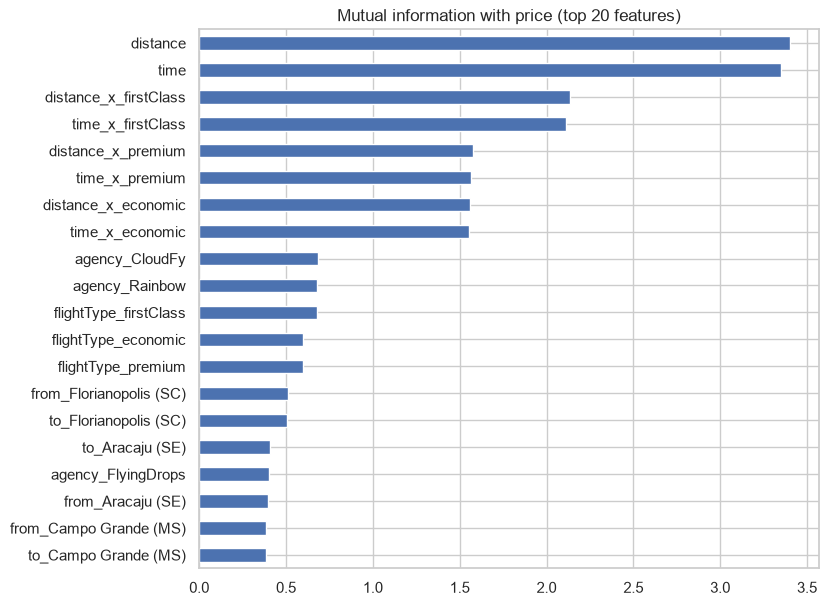

model inputs: ['from', 'to', 'flightType', 'agency', 'time', 'distance', 'date']


In [35]:
# Select your features wisely to avoid overfitting
fe = add_engineered_features(df.sample(30000, random_state=RANDOM_STATE))
X_mi = pd.get_dummies(fe[CATEGORICAL + NUMERIC], columns=CATEGORICAL, dtype=float)
mi = pd.Series(mutual_info_regression(X_mi, fe["price"], random_state=RANDOM_STATE), index=X_mi.columns)
mi.sort_values(ascending=False).head(20).plot(kind="barh", figsize=(8, 7))
plt.gca().invert_yaxis()
plt.title("Mutual information with price (top 20 features)")
plt.show()

# IDs and leaky columns are excluded on purpose
DROPPED = ["travelCode", "userCode", "price_per_km", "route", "day_name", "year"]
FEATURES = CATEGORICAL + ["time", "distance", "date"]   # raw inputs the pipeline/API receives
print("model inputs:", FEATURES)

##### What all feature selection methods have you used  and why?

* **Domain/leakage filtering:** removed `travelCode` and `userCode` (identifiers with no causal link to price) and `price_per_km` (computed from the target, so pure leakage).
* **Correlation analysis** (Chart 14) to spot redundancy: `time` ≈ `distance`.
* **Mutual information** (above) to rank features by their non-linear dependence with price. MI captures relationships that correlation misses, such as the categorical effects.
* **Model-based importance** (permutation importance on the final model, section 7) to confirm what the model actually uses.

##### Which all features you found important and why?

The most important features are the **distance × class interactions**, `distance`/`time`, the **flight class** and the route cities. That matches the pricing logic seen in Chart 6 (price ≈ class rate × distance + route adjustment). Calendar features score near zero, as the seasonality and weekday analysis predicted, but I keep them (they're cheap) so the model can pick up seasonal pricing if the business introduces it later.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [36]:
# Transform Your data
print(f"price skew = {df['price'].skew():.2f}, log(price) skew = {np.log(df['price']).skew():.2f}")
# skew is already small (0.31) - no log transform needed; the interaction features are the useful transformation

price skew = 0.31, log(price) skew = -0.38


The target's skew is only 0.31 and the relationship with distance is linear, so a log or Box-Cox transform isn't needed (it would also make the errors harder to explain in R$). The useful transformation here is the interaction features created above.

### 6. Data Scaling

In [37]:
# Scaling your data
def build_preprocessor(scale_numeric: bool) -> Pipeline:
    """One-hot encode categoricals; scale numerics only for the linear model."""
    columns = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL),
        ("num", StandardScaler() if scale_numeric else "passthrough", NUMERIC),
    ], verbose_feature_names_out=False)
    return Pipeline([("engineer", FunctionTransformer(add_engineered_features)), ("columns", columns)])

##### Which method have you used to scale you data and why?

I used **StandardScaler** (zero mean, unit variance) for the numeric features, **only for Ridge regression**. Ridge's L2 penalty is scale-sensitive, so un-scaled distance (hundreds of km) and binary flags would be penalised unequally. Tree-based models split on thresholds and aren't affected by scaling, so for them the numerics pass through unchanged.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. After encoding there are only ~35 features against 270k rows, so there is no curse of dimensionality. PCA would also destroy the interpretability of the features (class, route) that the business needs to understand prices.

In [38]:
# DImensionality Reduction (If needed)
# Not needed - see explanation above.

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None was used.

### 8. Data Splitting

In [39]:
# Split your data to train and test. Choose Splitting ratio wisely.
X = df[FEATURES]
y = df["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"train: {len(X_train):,} rows | test: {len(X_test):,} rows")

# second, harder evaluation: hold out whole routes (A-B and B-A together)
route_groups = df[["from", "to"]].apply(lambda r: "|".join(sorted(r)), axis=1)
print("undirected routes:", route_groups.nunique())

train: 217,510 rows | test: 54,378 rows


undirected routes: 35


##### What data splitting ratio have you used and why? 

I used an **80/20 random split** (≈217k training rows, ≈54k test rows). With this much data, 20% gives a very stable test estimate while leaving plenty for training.

Because the prices come from a tariff table, a random split puts every route in both train and test. So I also use a **GroupKFold split by route**, where the model never sees the held-out routes during training. It answers a different business question: *how well would we price a brand-new route?*

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

Imbalance applies to classification targets; here the target is continuous. The inputs are reasonably balanced (classes 29/29/43%, cities 9–13% each), and the price distribution has no rare extreme region (no outliers). So no re-balancing is needed.

In [40]:
# Handling Imbalanced Dataset (If needed)
# Not needed for this regression problem.

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

None. See above.

## ***7. ML Model Implementation***

In [41]:
# helper functions shared by all models
results = {}


def evaluate(name, model, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test):
    """Compute train/test metrics and store them for the final comparison."""
    scores = {}
    for split, X_, y_ in (("train", X_tr, y_tr), ("test", X_te, y_te)):
        pred = model.predict(X_)
        scores[split] = {"RMSE": np.sqrt(mean_squared_error(y_, pred)), "MAE": mean_absolute_error(y_, pred),
                         "R2": r2_score(y_, pred), "MAPE %": 100 * mean_absolute_percentage_error(y_, pred)}
    results[name] = scores["test"]
    return pd.DataFrame(scores).T.round(4)


def plot_scores(table, title):
    """Bar chart of train vs test metrics."""
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
    for a, metric in zip(ax, ["RMSE", "MAE", "R2"]):
        table[metric].plot(kind="bar", ax=a, color=["#4C72B0", "#DD8452"])
        a.set_title(metric)
        a.tick_params(axis="x", rotation=0)
        for c in a.containers:
            a.bar_label(c, fmt="%.3f")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def unseen_route_score(pipe, sample_size=60000, folds=3):
    """GroupKFold on routes - how well does the model price routes it has never seen?"""
    idx = X_train.sample(sample_size, random_state=RANDOM_STATE).index
    Xs, ys, gs = X_train.loc[idx], y_train.loc[idx], route_groups.loc[idx]
    rmse, r2 = [], []
    for tr, te in GroupKFold(folds).split(Xs, ys, gs):
        p = clone(pipe).fit(Xs.iloc[tr], ys.iloc[tr]).predict(Xs.iloc[te])   # clone: never refit the original
        rmse.append(np.sqrt(mean_squared_error(ys.iloc[te], p)))
        r2.append(r2_score(ys.iloc[te], p))
    return {"RMSE": np.mean(rmse), "R2": np.mean(r2)}

### ML Model - 1 - Ridge Regression (baseline)

In [42]:
# ML Model - 1 Implementation
ridge = Pipeline([("preprocess", build_preprocessor(scale_numeric=True)), ("model", Ridge(alpha=1.0))])

# Fit the Algorithm
ridge.fit(X_train, y_train)

# Predict on the model
ridge_table = evaluate("Ridge", ridge)
ridge_table

,RMSE,MAE,R2,MAPE %
train,87.8315,67.6381,0.9412,8.4541
test,87.9110,67.5899,0.9413,8.4534


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

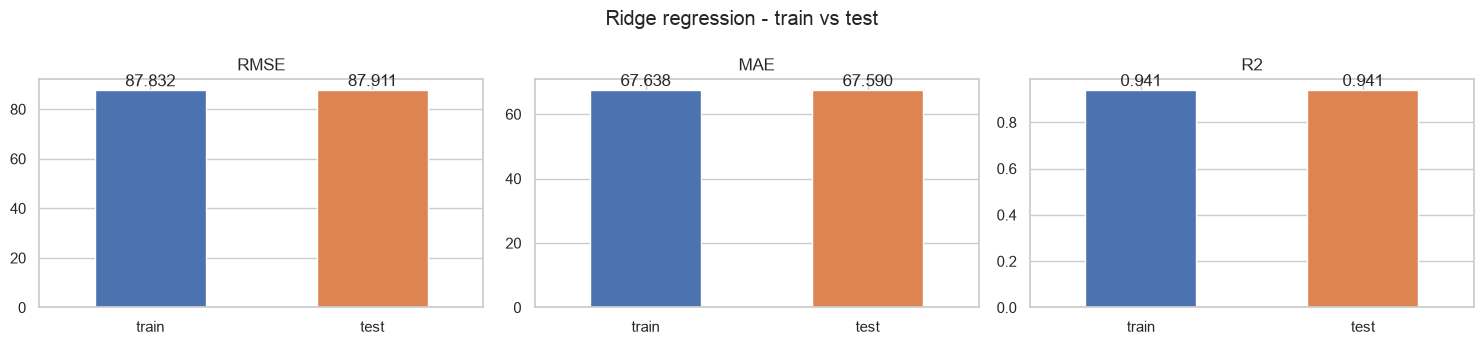

In [43]:
# Visualizing evaluation Metric Score chart
plot_scores(ridge_table, "Ridge regression - train vs test")

**Ridge regression** is linear regression with an L2 penalty that shrinks coefficients and handles the collinear `time`/`distance` pair gracefully. Thanks to the distance × class interactions it learns one price-per-km slope per class and explains about **94% of the variance** (R² ≈ 0.94), with a typical error (MAE) of about R$68. Train and test scores are almost identical, so there is no overfitting. It is a solid, interpretable baseline, but it can't capture the route-specific price adjustments.

#### 2. Cross- Validation & Hyperparameter Tuning

best params: {'model__alpha': 0.01} | CV RMSE: 87.826


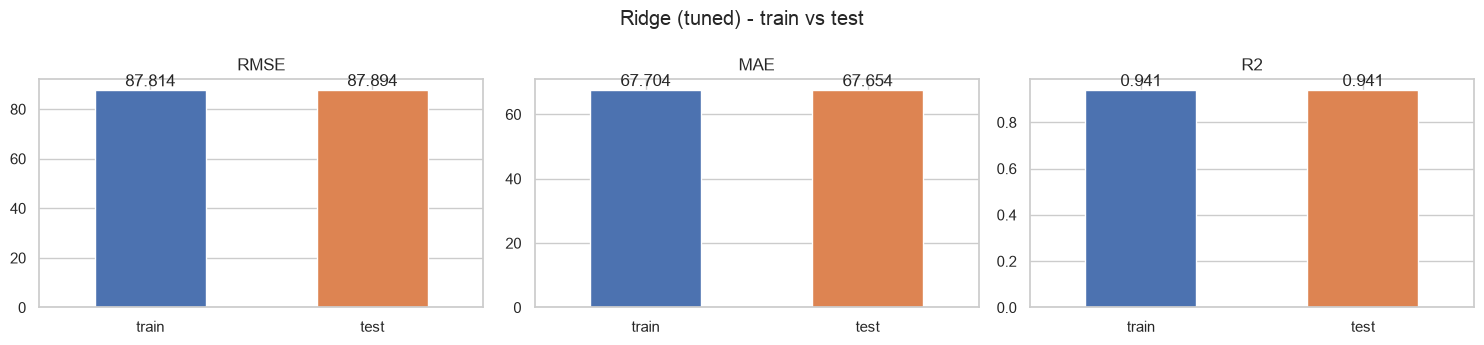

,RMSE,MAE,R2,MAPE %
train,87.8141,67.7036,0.9412,8.4594
test,87.8942,67.6542,0.9414,8.4585


In [44]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
ridge_grid = GridSearchCV(
    ridge, param_grid={"model__alpha": [0.01, 0.1, 1, 10, 100]},
    cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring="neg_root_mean_squared_error", n_jobs=-1)

# Fit the Algorithm
ridge_grid.fit(X_train, y_train)
print("best params:", ridge_grid.best_params_, "| CV RMSE:", round(-ridge_grid.best_score_, 3))

# Predict on the model
ridge_tuned = ridge_grid.best_estimator_
ridge_tuned_table = evaluate("Ridge (tuned)", ridge_tuned)
plot_scores(ridge_tuned_table, "Ridge (tuned) - train vs test")
ridge_tuned_table

##### Which hyperparameter optimization technique have you used and why?

**GridSearchCV with 5-fold cross-validation.** Ridge has a single important hyperparameter (`alpha`) and fits in under a second, so an exhaustive grid over a log scale is cheap and guarantees the best value in the grid is found.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Practically none: the scores barely change across alpha values. With 217k rows and ~35 features the model is far from overfitting, so regularisation strength hardly matters. Ridge's limit is model capacity, not tuning, which motivates the non-linear models below.

### ML Model - 2 - Random Forest Regressor

In [45]:
# ML Model - 2 Implementation
rf = Pipeline([("preprocess", build_preprocessor(scale_numeric=False)),
               ("model", RandomForestRegressor(n_estimators=60, max_depth=20, min_samples_leaf=5,
                                               n_jobs=-1, random_state=RANDOM_STATE))])
# Fit the Algorithm
rf.fit(X_train, y_train)
# Predict on the model
rf_table = evaluate("Random Forest", rf)
rf_table

,RMSE,MAE,R2,MAPE %
train,0.7999,0.0904,1.0,0.0186
test,0.8126,0.0924,1.0,0.0189


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

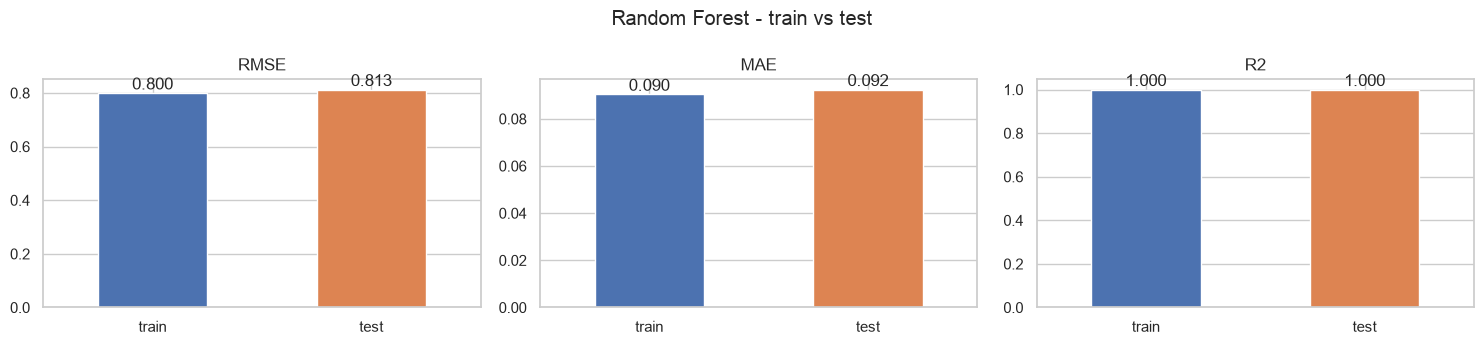

In [46]:
# Visualizing evaluation Metric Score chart
plot_scores(rf_table, "Random Forest - train vs test")

A **Random Forest** averages many decision trees, each trained on a bootstrap sample with random feature subsets. Trees can learn the exact route × class × agency tariff, so the forest reaches **R² ≈ 1.0 with an MAE of a few cents**. Train and test errors are equally tiny because the test set contains the same tariffs. It is far more accurate than Ridge for known routes.

#### 2. Cross- Validation & Hyperparameter Tuning

best params: {'model__n_estimators': 60, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 20} | CV RMSE: 0.96


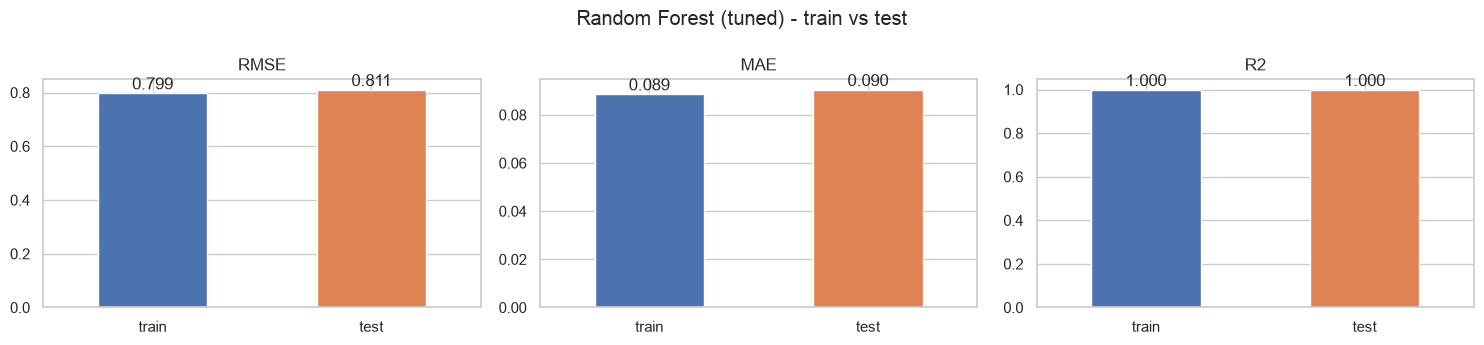

,RMSE,MAE,R2,MAPE %
train,0.7986,0.0887,1.0,0.0184
test,0.8110,0.0905,1.0,0.0187


In [47]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
tune_idx = X_train.sample(40000, random_state=RANDOM_STATE).index      # tune on a sample to keep it fast
rf_search = RandomizedSearchCV(
    rf, n_iter=6, random_state=RANDOM_STATE, n_jobs=-1,
    param_distributions={"model__n_estimators": [40, 60, 100], "model__max_depth": [12, 20, None],
                         "model__min_samples_leaf": [1, 5, 10], "model__max_features": [1.0, 0.7, 0.5]},
    cv=KFold(3, shuffle=True, random_state=RANDOM_STATE), scoring="neg_root_mean_squared_error")

# Fit the Algorithm
rf_search.fit(X_train.loc[tune_idx], y_train.loc[tune_idx])
print("best params:", rf_search.best_params_, "| CV RMSE:", round(-rf_search.best_score_, 3))

# Predict on the model (refit best params on the full training set)
rf_tuned = clone(rf).set_params(**rf_search.best_params_).fit(X_train, y_train)
rf_tuned_table = evaluate("Random Forest (tuned)", rf_tuned)
plot_scores(rf_tuned_table, "Random Forest (tuned) - train vs test")
rf_tuned_table

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** (6 random combinations, 3-fold CV) on a 40k-row sample. A Random Forest has several interacting hyperparameters and each fit is relatively expensive, so random search covers the space far more efficiently than a full grid. Tuning on a sample keeps it fast, and the best parameters are then refit on the full training set.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The forest was already near-perfect, so tuning only moves the RMSE by a fraction of a Real (see the chart above). Both versions are effectively exact on known routes. The interesting differences between models only show up in the unseen-route evaluation below.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **RMSE** (root mean squared error, in R$) penalises big mistakes more than small ones. A large pricing error on one ticket is what upsets a customer or loses margin, so this is my main selection metric.
* **MAE** (mean absolute error, in R$) is the typical error per ticket and the easiest to explain to the business: *"on average we're off by X Reais"*.
* **R²** is the share of price variation the model explains, a scale-free way to compare models.
* **MAPE** (percent error) puts the error relative to the ticket price, which is useful because R$20 matters more on a R$300 economy ticket than on a R$1,700 first-class one.

With errors of a few cents, the Random Forest can quote prices that match the tariff exactly. That removes manual price look-ups and lets the platform show prices instantly in search results.

### ML Model - 3 - Histogram Gradient Boosting Regressor

In [48]:
# ML Model - 3 Implementation
hgb = Pipeline([("preprocess", build_preprocessor(scale_numeric=False)),
                ("model", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
                                                        random_state=RANDOM_STATE))])
# Fit the Algorithm
hgb.fit(X_train, y_train)
# Predict on the model
hgb_table = evaluate("Gradient Boosting", hgb)
hgb_table

,RMSE,MAE,R2,MAPE %
train,0.1452,0.1123,1.0,0.0146
test,0.1461,0.1128,1.0,0.0147


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

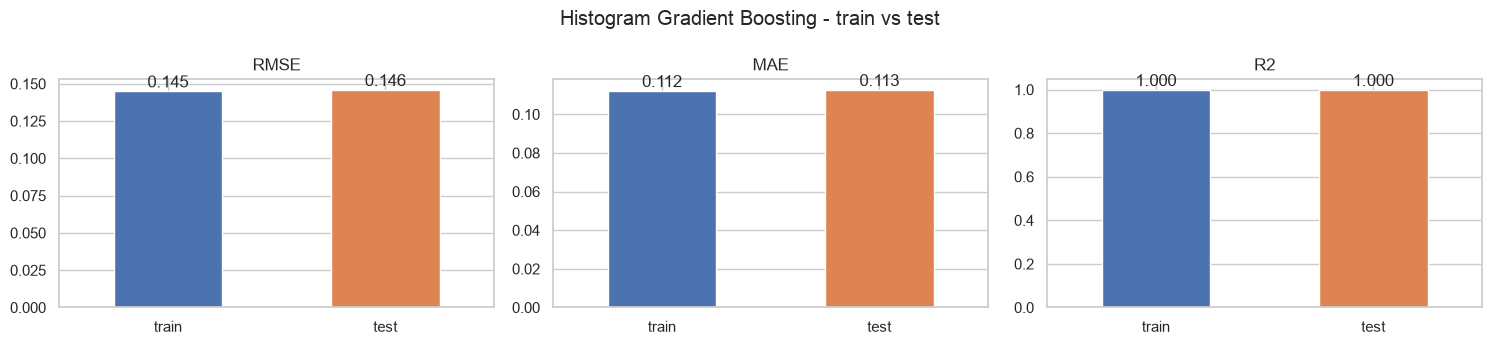

In [49]:
# Visualizing evaluation Metric Score chart
plot_scores(hgb_table, "Histogram Gradient Boosting - train vs test")

**Histogram Gradient Boosting** builds trees sequentially, with each new tree correcting the errors of the previous ones, on binned features (fast on large data, like LightGBM). Even with default settings it reaches **R² ≈ 1.000 with an RMSE of about R$0.15** on the test set, and it trains in seconds.

#### 2. Cross- Validation & Hyperparameter Tuning

best params: {'model__max_leaf_nodes': 63, 'model__max_iter': 300, 'model__learning_rate': 0.2, 'model__l2_regularization': 0.0} | CV RMSE: 0.321


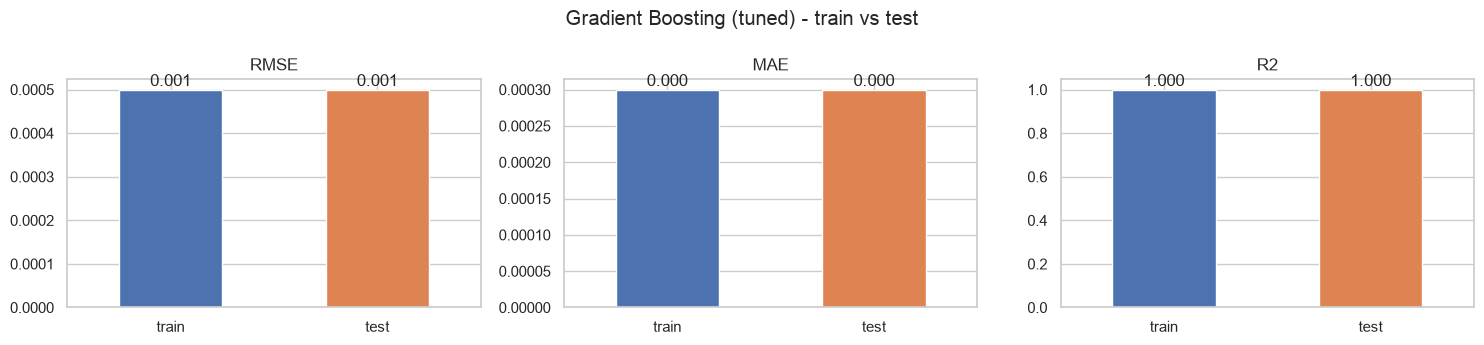

,RMSE,MAE,R2,MAPE %
train,0.0005,0.0003,1.0,0.0
test,0.0005,0.0003,1.0,0.0


In [50]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
hgb_search = RandomizedSearchCV(
    hgb, n_iter=8, random_state=RANDOM_STATE, n_jobs=-1,
    param_distributions={"model__learning_rate": [0.05, 0.1, 0.2], "model__max_iter": [200, 300, 500],
                         "model__max_leaf_nodes": [31, 63, 127], "model__l2_regularization": [0.0, 0.1, 1.0]},
    cv=KFold(3, shuffle=True, random_state=RANDOM_STATE), scoring="neg_root_mean_squared_error")

# Fit the Algorithm
hgb_search.fit(X_train.loc[tune_idx], y_train.loc[tune_idx])
print("best params:", hgb_search.best_params_, "| CV RMSE:", round(-hgb_search.best_score_, 3))

# Predict on the model
hgb_tuned = clone(hgb).set_params(**hgb_search.best_params_).fit(X_train, y_train)
hgb_tuned_table = evaluate("Gradient Boosting (tuned)", hgb_tuned)
plot_scores(hgb_tuned_table, "Gradient Boosting (tuned) - train vs test")
hgb_tuned_table

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** (8 combinations, 3-fold CV) over learning rate, number of iterations, tree size and L2 regularisation, for the same reasons as the Random Forest: several interacting hyperparameters, and random search finds good regions quickly.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes. The search picked a higher learning rate (0.2) with 300 iterations and 63 leaves, and the test RMSE dropped from ≈ R$0.15 to **≈ R$0.0005**, so the model now reproduces the tariff almost exactly. In absolute terms both versions are within cents, but the tuned one is clearly the best model in the comparison below, and I used these parameters in the production training script.

### Model comparison: known routes vs unseen routes

,RMSE,MAE,R2,MAPE %
Gradient Boosting (tuned),0.0005,0.0003,1.0000,0.0000
Gradient Boosting,0.1461,0.1128,1.0000,0.0147
Random Forest (tuned),0.8110,0.0905,1.0000,0.0187
Random Forest,0.8126,0.0924,1.0000,0.0189
Ridge (tuned),87.8942,67.6542,0.9414,8.4585
Ridge,87.9110,67.5899,0.9413,8.4534


,RMSE,R2
Ridge,128.709,0.866
Random Forest,195.260,0.695
Gradient Boosting,181.351,0.736


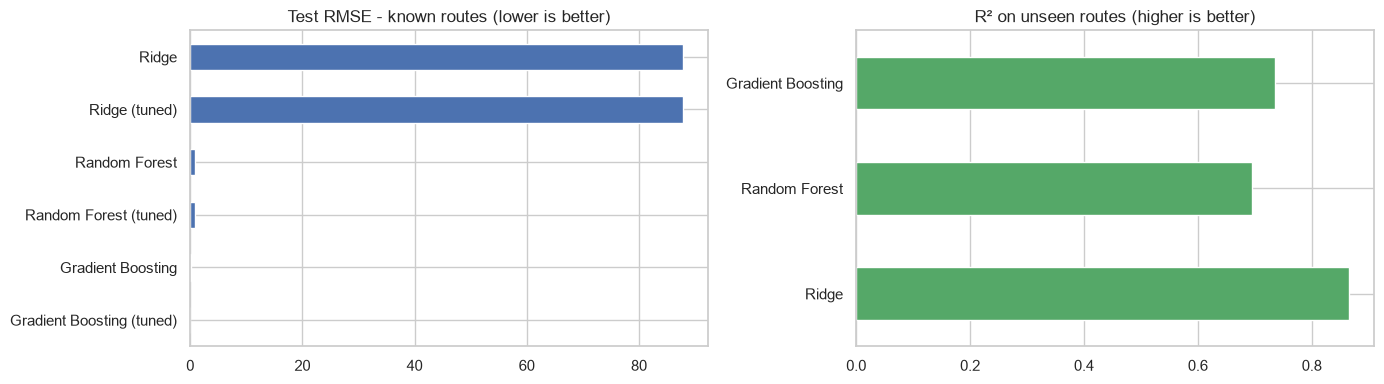

In [51]:
# compare all models on the random test split
comparison = pd.DataFrame(results).T.round(4).sort_values("RMSE")
display(comparison)

# robustness: price routes the model has never seen (GroupKFold by route)
candidates = {"Ridge": ridge_tuned, "Random Forest": rf_tuned, "Gradient Boosting": hgb_tuned}
unseen = pd.DataFrame({name: unseen_route_score(m) for name, m in candidates.items()}).T.round(3)
display(unseen)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
comparison["RMSE"].plot(kind="barh", ax=ax[0], color="#4C72B0", title="Test RMSE - known routes (lower is better)")
unseen["R2"].plot(kind="barh", ax=ax[1], color="#55A868", title="R² on unseen routes (higher is better)")
plt.tight_layout()
plt.show()

On **known routes**, the tree models are essentially exact (RMSE < R$1, tuned Gradient Boosting ≈ R$0.0005), while Ridge's RMSE is ≈ R$88.

On **unseen routes** the picture flips: Ridge generalises best (R² ≈ 0.87) because it learned the *price-per-km* rule, while the trees reach only about 0.69–0.74 because they partly memorised route prices. No model can know a new route's specific adjustment, and that is where the remaining error comes from.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**RMSE** is the primary metric because large pricing errors are the costly ones (a lost customer or lost margin), and RMSE penalises them most. I report **MAE** as the easy-to-explain average error in R$, **R²** to compare models, and **MAPE** to judge errors relative to the ticket price. I also track **unseen-route R²** as a robustness metric for expansion to new routes.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

I chose **Histogram Gradient Boosting** as the production model:
1. It has the **lowest test RMSE** (≈ R$0.0005 after tuning), so it reproduces the tariff for all routes the business currently sells.
2. Among the tree models it generalises best to unseen routes (R² ≈ 0.74 vs 0.69 for the Random Forest).
3. It is fast to train (seconds) and the saved model is small (< 1 MB), which suits Docker images and quick Kubernetes rollouts.

The Ridge model stays useful as a **fallback for brand-new routes**. The production pipeline logs the unseen-route score to MLflow for every training run.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

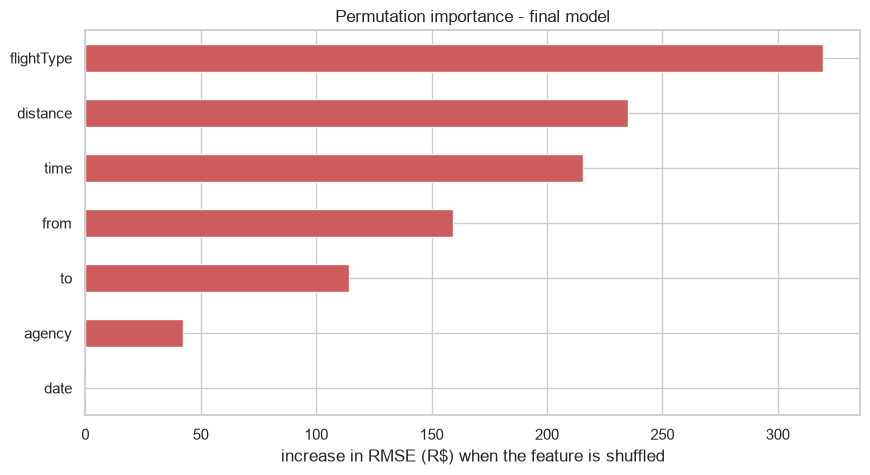

flightType    319.78
distance      235.02
time          215.56
from          159.20
to            114.30
agency         42.19
date            0.02
dtype: float64

In [52]:
# permutation importance: how much does test RMSE increase when one raw input is shuffled?
final_model = hgb_tuned
sample_idx = X_test.sample(5000, random_state=RANDOM_STATE).index
perm = permutation_importance(final_model, X_test.loc[sample_idx], y_test.loc[sample_idx], n_repeats=5,
                              random_state=RANDOM_STATE, scoring="neg_root_mean_squared_error", n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
importance.plot(kind="barh", color="indianred")
plt.xlabel("increase in RMSE (R$) when the feature is shuffled")
plt.title("Permutation importance - final model")
plt.show()
importance.sort_values(ascending=False).round(2)

I used **permutation importance**, a model-agnostic explainability method: shuffle one input column and measure how much the error grows. Because it runs on the raw inputs of the whole pipeline, the result is easy to explain to the business.

* **flightType** is by far the most important input: shuffling it increases the error by hundreds of Reais.
* **distance/time** come next: they set the base fare.
* **from/to** capture the route-specific adjustment.
* **agency** matters a little (FlyingDrops and the small agency differences).
* **date** is essentially unused, which matches the hypothesis test showing no weekend or seasonal surcharge.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [53]:
# Save the File
MODEL_FILE = "flight_price_model_notebook.joblib"
joblib.dump(final_model, MODEL_FILE, compress=3)
print(f"saved {MODEL_FILE} ({os.path.getsize(MODEL_FILE) / 1024:.0f} KB)")
# Note: the production artefact (models/flight_price_model.joblib) is produced by
# src/travel_ml/train_regression.py, which uses this exact pipeline and logs every run to MLflow.

saved flight_price_model_notebook.joblib (808 KB)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [54]:
# Load the File and predict unseen data.
loaded = joblib.load(MODEL_FILE)

# new requests exactly as the REST API would receive them; time/distance come from the route table
route_info = df.drop_duplicates(["from", "to"]).set_index(["from", "to"])[["time", "distance"]]
new_flights = pd.DataFrame([
    {"from": "Recife (PE)", "to": "Florianopolis (SC)", "flightType": "firstClass", "agency": "FlyingDrops",
     "date": "2024-09-26"},
    {"from": "Sao Paulo (SP)", "to": "Natal (RN)", "flightType": "economic", "agency": "CloudFy",
     "date": "2024-12-20"},
    {"from": "Brasilia (DF)", "to": "Salvador (BH)", "flightType": "premium", "agency": "Rainbow",
     "date": "2025-01-05"},
])
new_flights = new_flights.join(route_info, on=["from", "to"])
new_flights["predicted_price"] = loaded.predict(new_flights).round(2)

# compare with the tariff seen in the data for the same route/class/agency
tariff = df.groupby(["from", "to", "flightType", "agency"])["price"].first()
new_flights["tariff_price"] = [tariff.get((r["from"], r["to"], r["flightType"], r["agency"]))
                               for _, r in new_flights.iterrows()]
new_flights

,from,to,flightType,agency,date,time,distance,predicted_price,tariff_price
0,Recife (PE),Florianopolis (SC),firstClass,FlyingDrops,2024-09-26,1.76,676.53,1434.38,1434.38
1,Sao Paulo (SP),Natal (RN),economic,CloudFy,2024-12-20,0.85,327.55,488.57,488.57
2,Brasilia (DF),Salvador (BH),premium,Rainbow,2025-01-05,1.76,676.56,1268.97,1268.97


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

**How the model is deployed (see the GitHub repo):**
* `src/travel_ml/train_regression.py`: trains all candidates, logs params/metrics/models to **MLflow**, registers the best in the model registry and moves the `@champion` alias only if it beats the current champion.
* `api/app.py`: **Flask REST API** (`/predict`, `/health`, `/ready`, `/metrics`) with input validation and prediction logging.
* `docker/Dockerfile.api`: **Docker** image served by gunicorn.
* `k8s/`: **Kubernetes** Deployment (2 replicas, probes, rolling updates), NodePort Service and CPU-based **HPA** (2–6 pods).
* `airflow/dags/`: weekly retraining DAG and daily **drift-monitoring** DAG (PSI) that triggers retraining.
* `Jenkinsfile`: **CI/CD** with lint → tests → retrain (optional) → model quality gate → build → smoke test → push → deploy → automatic rollback on failure.

# **Conclusion**

* The flights data is clean (no missing values, duplicates or outliers), and its prices follow a **deterministic tariff**: route + class + agency always give the same price.
* EDA and hypothesis tests show that **class and distance drive price**: first class costs ~1.8× economy, the price-per-km slope differs by class, agency differences are tiny, and there is no seasonal or weekend surcharge once the route mix is controlled for.
* Feature engineering (one-hot encoding plus **distance × class interactions**) lifted the linear baseline to R² ≈ 0.94.
* **Histogram Gradient Boosting** was selected (tuned test RMSE < R$0.01, R² ≈ 1.000). It reproduces the tariff for every known route and is the best tree model on unseen routes. The linear model is the better choice if the company opens many new routes.
* The model is production-ready: it is served through a Flask REST API, containerised with Docker, scaled with Kubernetes, retrained and monitored by Airflow, versioned in MLflow and deployed through Jenkins.

**Future work:** add real-time demand and seasonality signals (booking lead time, seat availability) so the model can support dynamic pricing, add authentication and rate limiting to the API, and move the stack to a managed cloud cluster with Prometheus/Grafana dashboards.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***